### Objetivo de esta notebook
Construir la tabla agregada a nivel **equipo-temporada** (unificando partidos de local y de visitante en promedios por partido), realizar el Análisis Exploratorio de Datos (AED) de las 12 variables de juego y aplicar las decisiones de preprocesamiento requeridas por **K-Means** (filtro de multicolinealidad/redundancia, tratamiento de outliers y estandarización con `StandardScaler`).

**Archivos de salida generados:**
1. `data/processed/tabla_equipo_temporada.csv`: Tabla completa con las métricas de juego y las variables de contexto (`puntos`, `posicion`, `top4`, `es_britanico`) para interpretar los clusters.
2. `data/processed/features_clustering.csv`: Matriz numérica limpia, recortada y escalada que ingresa directamente al algoritmo de clustering.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold"
})

# Cargar dataset consolidado
ruta_entrada = next(
    p for p in ["../data/processed/dataset_final_modelo.csv", "data/processed/dataset_final_modelo.csv"]
    if os.path.exists(p)
)
df = pd.read_csv(ruta_entrada, low_memory=False)
df["Date"] = pd.to_datetime(df["Date"])
df["temp_inicio"] = df["temporada_origen"].str.extract(r"season_(\d{4})").astype(int)
df["temporada"] = df["temp_inicio"].astype(str) + "-" + ((df["temp_inicio"] + 1) % 100).astype(str).str.zfill(2)

# Filtrar desde 2000/01 (período donde se registran tiros, córners, faltas y tarjetas al 100%)
cols_partido = ["FTHG", "FTAG", "HS", "AS", "HST", "AST", "HF", "AF", "HC", "AC", "HY", "AY", "HR", "AR"]
df_stats = df[df["temp_inicio"] >= 2000].dropna(subset=cols_partido).copy()

print(f"Partidos con estadísticas completas (2000/01 a 2025/26): {len(df_stats)} partidos en {df_stats['temporada'].nunique()} temporadas.")

Partidos con estadísticas completas (2000/01 a 2025/26): 9790 partidos en 26 temporadas.


C:\Users\Dante\AppData\Local\Temp\ipykernel_7336\1714526376.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["temp_inicio"] = df["temporada_origen"].str.extract(r"season_(\d{4})").astype(int)
C:\Users\Dante\AppData\Local\Temp\ipykernel_7336\1714526376.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["temporada"] = df["temp_inicio"].astype(str) + "-" + ((df["temp_inicio"] + 1) % 100).astype(str).str.zfill(2)


Armado de la tabla por equipo y temporada (Local + Visitante)

In [2]:
# 1. Calcular puntos por partido
df_stats["puntos_home"] = np.select([df_stats["FTR"] == "H", df_stats["FTR"] == "D"], [3, 1], default=0)
df_stats["puntos_away"] = np.select([df_stats["FTR"] == "A", df_stats["FTR"] == "D"], [3, 1], default=0)

# 2. Apilar actuaciones de local y de visitante para cada equipo
local = pd.DataFrame({
    "temporada": df_stats["temporada"],
    "temp_inicio": df_stats["temp_inicio"],
    "equipo": df_stats["HomeTeam"],
    "tiros": df_stats["HS"],
    "tiros_al_arco": df_stats["HST"],
    "goles_a_favor": df_stats["FTHG"],
    "corners": df_stats["HC"],
    "goles_en_contra": df_stats["FTAG"],
    "tiros_en_contra": df_stats["AS"],
    "tiros_al_arco_en_contra": df_stats["AST"],
    "faltas": df_stats["HF"],
    "amarillas": df_stats["HY"],
    "rojas": df_stats["HR"],
    "puntos": df_stats["puntos_home"],
    "dt_nombre": df_stats["dt_home"],
    "es_britanico_dt": df_stats["es_britanico_dt_home"]
})

visitante = pd.DataFrame({
    "temporada": df_stats["temporada"],
    "temp_inicio": df_stats["temp_inicio"],
    "equipo": df_stats["AwayTeam"],
    "tiros": df_stats["AS"],
    "tiros_al_arco": df_stats["AST"],
    "goles_a_favor": df_stats["FTAG"],
    "corners": df_stats["AC"],
    "goles_en_contra": df_stats["FTHG"],
    "tiros_en_contra": df_stats["HS"],
    "tiros_al_arco_en_contra": df_stats["HST"],
    "faltas": df_stats["AF"],
    "amarillas": df_stats["AY"],
    "rojas": df_stats["AR"],
    "puntos": df_stats["puntos_away"],
    "dt_nombre": df_stats["dt_away"],
    "es_britanico_dt": df_stats["es_britanico_dt_away"]
})

partidos_equipo = pd.concat([local, visitante], ignore_index=True)

# 3. Agregación por equipo y temporada (todas las variables de juego son promedios por partido)
tabla_equipo_temporada = partidos_equipo.groupby(["temporada", "temp_inicio", "equipo"], as_index=False).agg(
    partidos_jugados=("puntos", "count"),
    # Ataque
    tiros=("tiros", "mean"),
    tiros_al_arco=("tiros_al_arco", "mean"),
    goles_a_favor=("goles_a_favor", "mean"),
    corners=("corners", "mean"),
    # Defensa
    goles_en_contra=("goles_en_contra", "mean"),
    tiros_en_contra=("tiros_en_contra", "mean"),
    tiros_al_arco_en_contra=("tiros_al_arco_en_contra", "mean"),
    # Disciplina
    faltas=("faltas", "mean"),
    amarillas=("amarillas", "mean"),
    rojas=("rojas", "mean"),
    # Totales para armar posición oficial
    puntos=("puntos", "sum"),
    gf_tot=("goles_a_favor", "sum"),
    gc_tot=("goles_en_contra", "sum")
)

# 4. Efectividad: precisión (tiros al arco / tiros) y conversión (goles / tiros al arco)
tabla_equipo_temporada["precision"] = tabla_equipo_temporada["tiros_al_arco"] / tabla_equipo_temporada["tiros"]
tabla_equipo_temporada["conversion"] = tabla_equipo_temporada["goles_a_favor"] / tabla_equipo_temporada["tiros_al_arco"]

# 5. DT que dirigió más partidos esa temporada y su origen (es_britanico)
dt_moda = (
    partidos_equipo.groupby(["temporada", "equipo", "dt_nombre", "es_britanico_dt"])
    .size()
    .reset_index(name="partidos_dt")
    .sort_values(["temporada", "equipo", "partidos_dt"], ascending=[True, True, False])
    .drop_duplicates(["temporada", "equipo"])
)
tabla_equipo_temporada = tabla_equipo_temporada.merge(
    dt_moda[["temporada", "equipo", "dt_nombre", "es_britanico_dt"]].rename(
        columns={"dt_nombre": "dt_principal", "es_britanico_dt": "es_britanico"}
    ),
    on=["temporada", "equipo"],
    how="left"
)
tabla_equipo_temporada["es_britanico"] = tabla_equipo_temporada["es_britanico"].astype(int)

# 6. Posición oficial (puntos -> diferencia de gol -> goles a favor) y Top 4
tabla_equipo_temporada["dif_gol"] = tabla_equipo_temporada["gf_tot"] - tabla_equipo_temporada["gc_tot"]
tabla_equipo_temporada = tabla_equipo_temporada.sort_values(
    ["temp_inicio", "puntos", "dif_gol", "gf_tot"],
    ascending=[True, False, False, False]
).reset_index(drop=True)
tabla_equipo_temporada["posicion"] = tabla_equipo_temporada.groupby("temporada").cumcount() + 1
tabla_equipo_temporada["top4"] = (tabla_equipo_temporada["posicion"] <= 4).astype(int)
tabla_equipo_temporada = tabla_equipo_temporada.drop(columns=["gf_tot", "gc_tot", "dif_gol"])

print(f"Dimensiones de tabla_equipo_temporada: {tabla_equipo_temporada.shape}")
tabla_equipo_temporada.head(5)

Dimensiones de tabla_equipo_temporada: (520, 21)


,temporada,temp_inicio,equipo,partidos_jugados,tiros,tiros_al_arco,goles_a_favor,corners,goles_en_contra,tiros_en_contra,...,faltas,amarillas,rojas,puntos,precision,conversion,dt_principal,es_britanico,posicion,top4
0,2000-01,2000,Manchester United,38,14.631579,6.947368,2.078947,7.078947,0.815789,8.815789,...,11.394737,1.157895,0.078947,80,0.474820,0.299242,Alex Ferguson,1,1,1
1,2000-01,2000,Arsenal,38,14.210526,7.763158,1.657895,7.763158,1.000000,8.000000,...,13.026316,1.263158,0.078947,70,0.546296,0.213559,Arsene Wenger,0,2,1
2,2000-01,2000,Liverpool,38,12.842105,6.552632,1.868421,6.394737,1.026316,8.973684,...,12.447368,1.315789,0.105263,69,0.510246,0.285141,Gerard Houllier,0,3,1
3,2000-01,2000,Leeds,38,12.500000,6.000000,1.684211,7.105263,1.131579,10.157895,...,15.500000,1.894737,0.078947,68,0.480000,0.280702,DT No Registrado,1,4,1
4,2000-01,2000,Ipswich,38,12.921053,5.947368,1.500000,5.421053,1.105263,9.868421,...,10.894737,0.815789,0.052632,66,0.460285,0.252212,DT No Registrado,1,5,0


AED de las 12 variables (Distribuciones, Asimetría y Outliers con IQR)

In [3]:
vars_clustering = [
    # Ataque
    "tiros", "tiros_al_arco", "goles_a_favor", "corners",
    # Efectividad
    "precision", "conversion",
    # Defensa
    "goles_en_contra", "tiros_en_contra", "tiros_al_arco_en_contra",
    # Disciplina
    "faltas", "amarillas", "rojas"
]

vars_interpretacion = ["temporada", "temp_inicio", "equipo", "puntos", "posicion", "top4", "dt_principal", "es_britanico"]

# Resumen estadístico + Asimetría (Skewness) + Conteo de Outliers por criterio IQR (1.5 * IQR)
q1 = tabla_equipo_temporada[vars_clustering].quantile(0.25)
q3 = tabla_equipo_temporada[vars_clustering].quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

outliers_iqr = ((tabla_equipo_temporada[vars_clustering] < lim_inf) | (tabla_equipo_temporada[vars_clustering] > lim_sup)).sum()

resumen_aed = tabla_equipo_temporada[vars_clustering].describe().T[["mean", "std", "min", "25%", "50%", "75%", "max"]]
resumen_aed["asimetria_skew"] = tabla_equipo_temporada[vars_clustering].skew()
resumen_aed["outliers_iqr"] = outliers_iqr
resumen_aed["%_outliers"] = (outliers_iqr / len(tabla_equipo_temporada) * 100).round(2)

display(resumen_aed.round(3))

,mean,std,min,25%,50%,75%,max,asimetria_skew,outliers_iqr,%_outliers
tiros,12.220,2.297,7.737,10.526,11.820,13.559,20.789,0.719,7,1.35
tiros_al_arco,5.294,1.536,2.605,4.039,5.092,6.158,10.500,0.766,8,1.54
goles_a_favor,1.359,0.419,0.526,1.079,1.263,1.605,2.789,0.845,11,2.12
corners,5.392,0.928,3.368,4.711,5.289,5.974,8.342,0.452,2,0.38
precision,0.435,0.101,0.271,0.342,0.417,0.535,0.636,0.114,0,0.00
conversion,0.264,0.068,0.110,0.210,0.260,0.318,0.431,0.157,0,0.00
goles_en_contra,1.359,0.347,0.364,1.132,1.342,1.579,2.737,0.192,4,0.77
tiros_en_contra,12.219,2.311,6.211,10.783,12.329,13.816,18.211,-0.094,1,0.19
tiros_al_arco_en_contra,5.294,1.454,2.184,4.263,5.026,6.306,10.026,0.480,1,0.19
faltas,11.504,1.491,7.553,10.447,11.320,12.461,16.263,0.381,6,1.15


Gráficos de Distribuciones (Histogramas + KDE) y Boxplots (IQR)

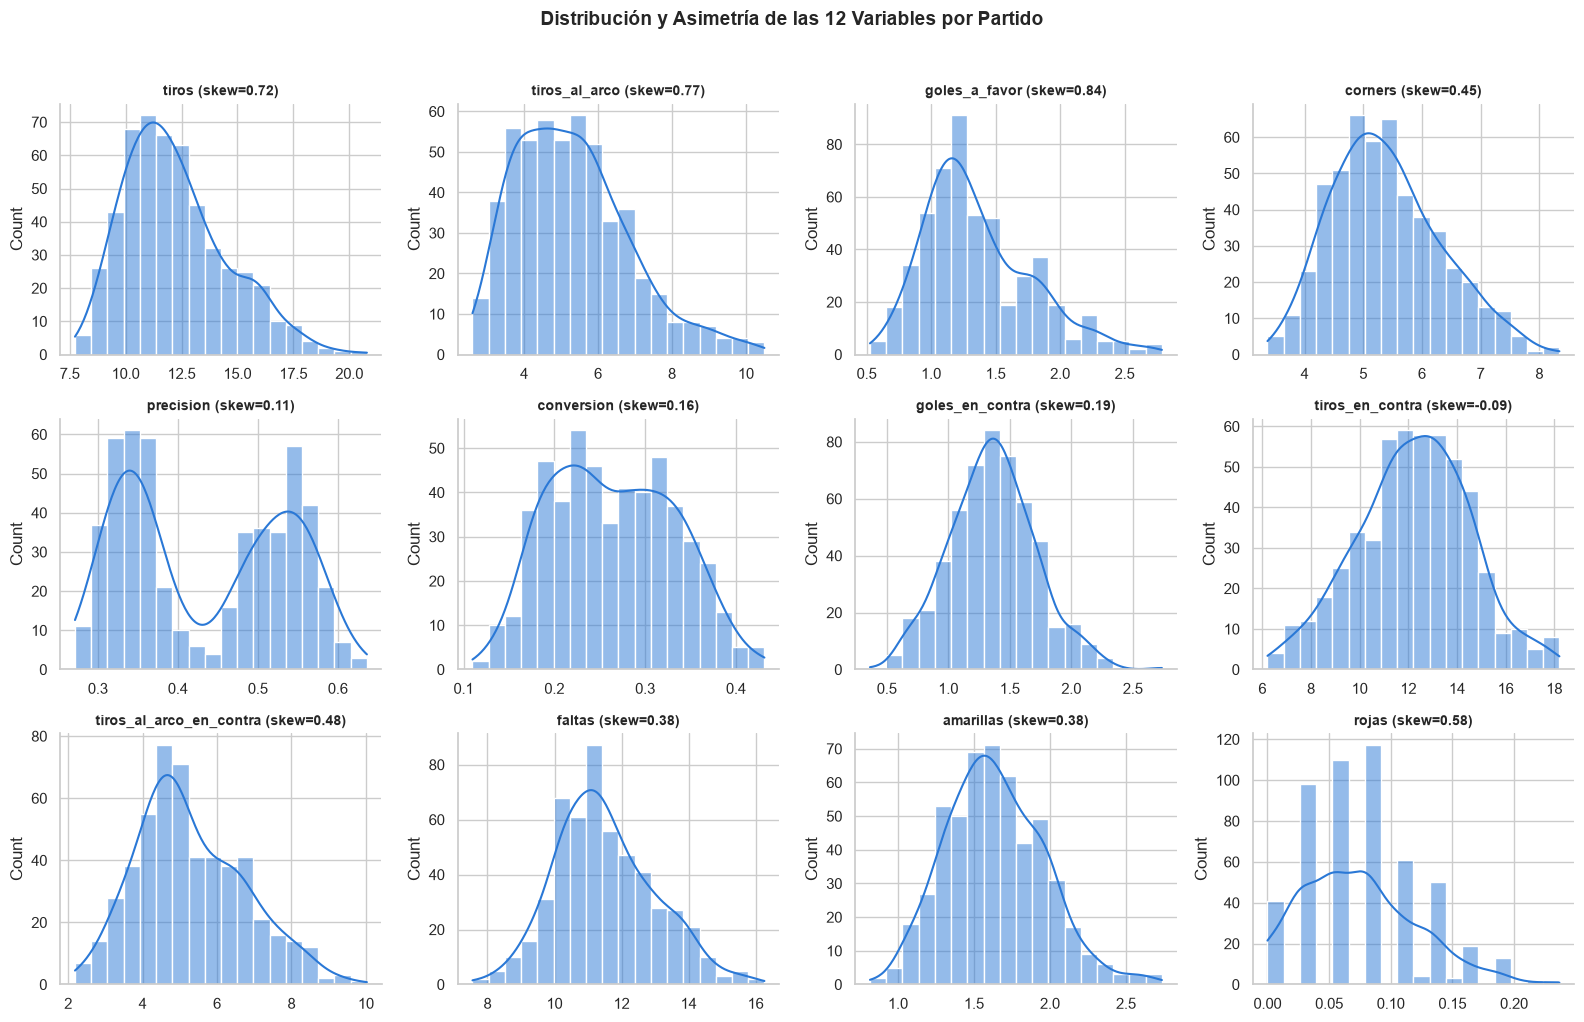

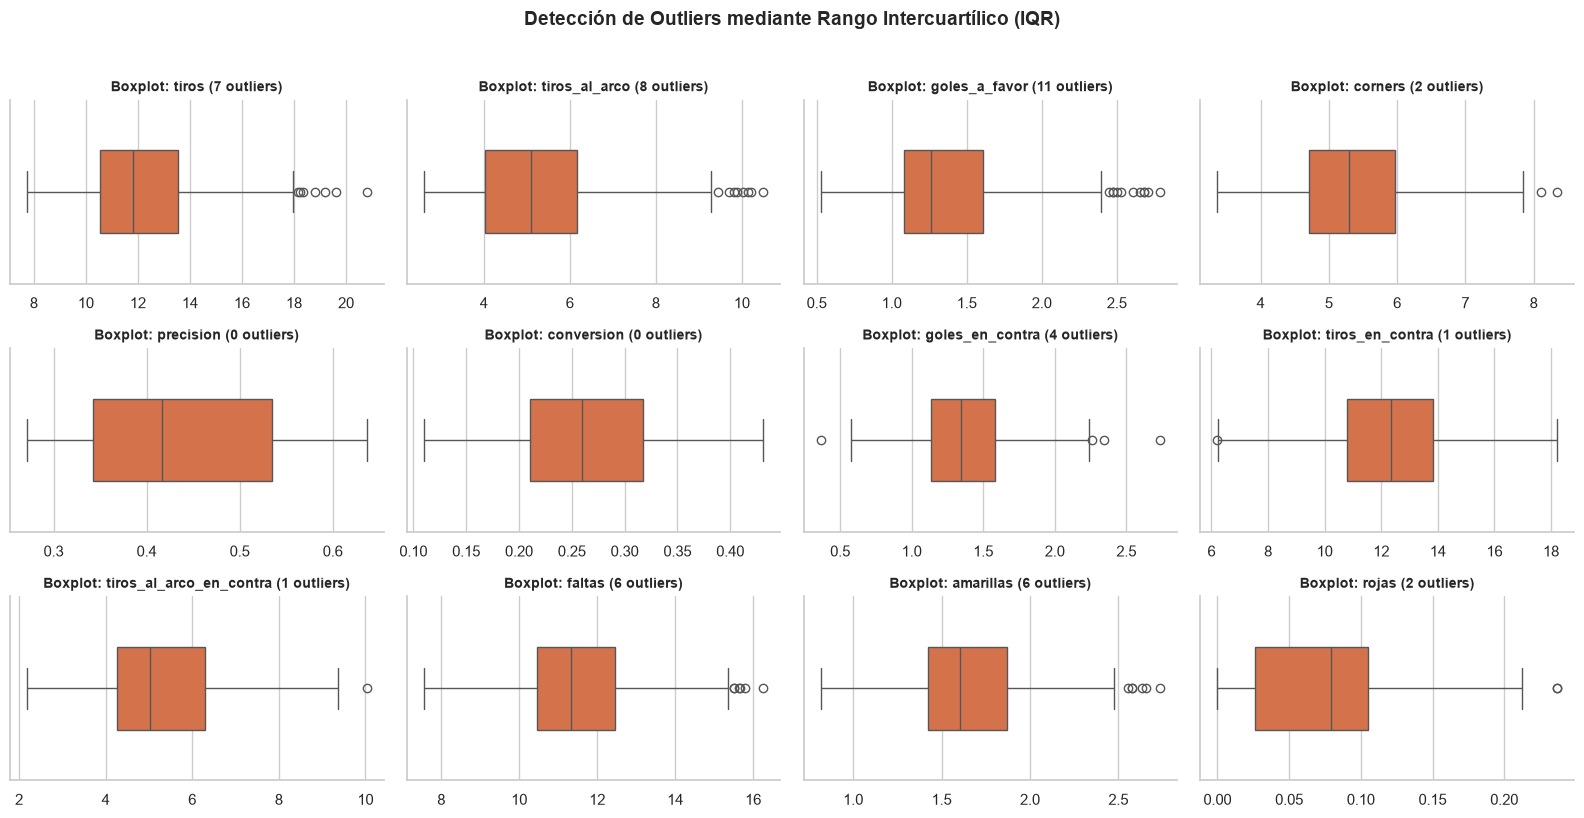

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, vars_clustering):
    sns.histplot(tabla_equipo_temporada[col], kde=True, ax=ax, color="#2a78d6", bins=18)
    ax.set_title(f"{col} (skew={tabla_equipo_temporada[col].skew():.2f})", fontsize=10)
    ax.set_xlabel("")
plt.suptitle("Distribución y Asimetría de las 12 Variables por Partido", fontsize=14, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, vars_clustering):
    sns.boxplot(x=tabla_equipo_temporada[col], ax=ax, color="#eb6834", width=0.45)
    ax.set_title(f"Boxplot: {col} ({outliers_iqr[col]} outliers)", fontsize=10)
    ax.set_xlabel("")
plt.suptitle("Detección de Outliers mediante Rango Intercuartílico (IQR)", fontsize=14, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

Celda 6 (Código): Matriz de Correlación y Análisis de Redundancia ($\vert{}r\vert{} > 0.85$)Hallazgo clave para lucirse en el Storytelling del grupo: En football-data.co.uk, a partir de la temporada 2013/14 cambió el proveedor estadístico (Opta dejó de contabilizar disparos bloqueados como tiros al arco HST/AST). Por eso, dentro de cada era (2000–2012 y 2013–2025), tiros vs. tiros_al_arco tienen una correlación de $r = 0.95$ y $r = 0.94$ respectivamente, y tiros_en_contra vs. tiros_al_arco_en_contra tienen $r = 0.95$ y $r = 0.91$ (superando ampliamente el umbral de $0.85$). Evaluamos la matriz global y por régimen para eliminar exactamente las variables redundantes:

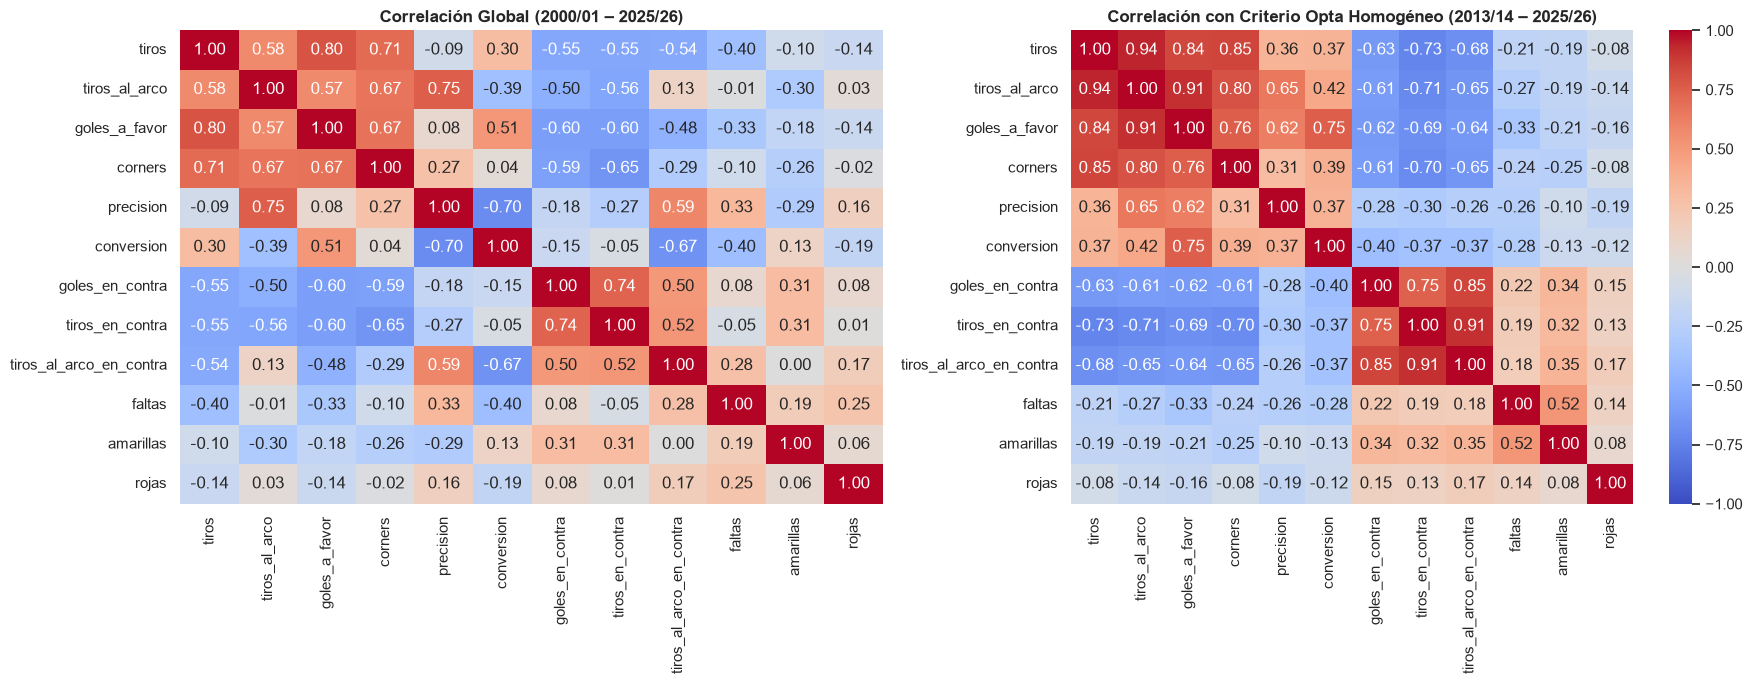

Pares de variables muy redundantes (|r| >= 0.85):
 • tiros vs. tiros_al_arco: r = 0.938
 • tiros_al_arco vs. goles_a_favor: r = 0.908
 • tiros_en_contra vs. tiros_al_arco_en_contra: r = 0.913


In [5]:
# Matriz de correlación global y en régimen de medición homogéneo (2013/14 - 2025/26)
corr_global = tabla_equipo_temporada[vars_clustering].corr()
corr_homogenea = tabla_equipo_temporada[tabla_equipo_temporada["temp_inicio"] >= 2013][vars_clustering].corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(corr_global, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title("Correlación Global (2000/01 – 2025/26)")

sns.heatmap(corr_homogenea, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlación con Criterio Opta Homogéneo (2013/14 – 2025/26)")
plt.tight_layout()
plt.show()

# Detectar pares con |r| > 0.85
umbral = 0.85
pares_redundantes = []
for i in range(len(vars_clustering)):
    for j in range(i + 1, len(vars_clustering)):
        v1, v2 = vars_clustering[i], vars_clustering[j]
        r_post = corr_homogenea.loc[v1, v2]
        if abs(r_post) >= umbral:
            pares_redundantes.append((v1, v2, round(r_post, 3)))

print("Pares de variables muy redundantes (|r| >= 0.85):")
for v1, v2, r in pares_redundantes:
    print(f" • {v1} vs. {v2}: r = {r}")

Las 3 Decisiones de Preprocesamiento con su Criterio por Escrito

## Decisiones de Preprocesamiento para K-Means (Criterios Explícitos)

Siguiendo las buenas prácticas de **K-Means (Clase 20)**, documentamos cada decisión tomada antes de ajustar el modelo:

### 1. Eliminación de variables muy redundantes (Criterio: $|r| > 0.85$)
* **Pares detectados con correlación $> 0.85$:**
  * `tiros` vs. `tiros_al_arco` ($r = 0.938$ post-2013 y $r = 0.951$ pre-2013).
  * `tiros_al_arco` vs. `goles_a_favor` ($r = 0.908$).
  * `tiros_en_contra` vs. `tiros_al_arco_en_contra` ($r = 0.913$ post-2013 y $r = 0.949$ pre-2013).
* **Decisión:** Eliminamos **`tiros_al_arco`** y **`tiros_al_arco_en_contra`**.
* **Por qué:** Si dejamos dos variables que miden prácticamente lo mismo, la distancia euclidiana de K-Means le da doble peso al volumen de remates. Además, `tiros_al_arco` ya está capturada en las tasas de efectividad (`precision = tiros_al_arco / tiros` y `conversion = goles_a_favor / tiros_al_arco`), y al quitar el conteo bruto de tiros al arco evitamos arrastrar el salto metodológico de proveedor de 2013/14.

### 2. Tratamiento de Outliers (Criterio: Recorte / Winsorizing a $[Q_1 - 1.5\text{ IQR}, Q_3 + 1.5\text{ IQR}]$)
* **Decisión:** **Recortamos (clipping / winsorizing)** los outliers a los bigotes del criterio IQR en lugar de eliminar filas o dejarlos crudos.
* **Por qué:** Como vimos en la Clase 20, **K-Means actualiza sus centroides calculando el promedio de las instancias asignadas y minimiza la suma de distancias al cuadrado** ($d(i) = ||X_i - C_j||^2$). Los valores extremos al elevarse al cuadrado desplazan los centroides y distorsionan los grupos. No debemos borrar las filas porque corresponden a equipos reales (ej. el Manchester City récord de 100 puntos o equipos que sufrieron goleadas históricas) que necesitamos clasificar e interpretar en la tabla final; al acotarlos en el umbral IQR conservamos las 520 filas en el extremo de su distribución sin deformar los centroides.

### 3. Escalado de Variables (Criterio: `StandardScaler`)
* **Decisión:** Estandarizamos todas las features seleccionadas a media $\mu = 0$ y desvío estándar $\sigma = 1$ con `StandardScaler`.
* **Por qué:** K-Means (y también DBSCAN y PCA/SVD) se basa en distancias geométricas. Sin escalar, variables de mayor magnitud numérica como `tiros` (rango $7.7$ a $20.8$) o `faltas` (rango $7.5$ a $16.3$) dominarían por completo el cálculo de la distancia frente a variables con decimales pequeños como `rojas` ($0.00$ a $0.24$), `conversion` ($0.11$ a $0.43$) o `precision` ($0.27$ a $0.64$).

Aplicación del Preprocesamiento y Guardado de los 2 Archivos CSV

In [6]:
# 1. Sacar variables redundantes (|r| > 0.85)
vars_eliminar = ["tiros_al_arco", "tiros_al_arco_en_contra"]
features_seleccionadas = [c for c in vars_clustering if c not in vars_eliminar]
print(f"Variables finales para el modelo ({len(features_seleccionadas)}): {features_seleccionadas}")

df_features = tabla_equipo_temporada[features_seleccionadas].copy()

# 2. Recortar outliers con criterio IQR (Winsorizing)
q1_sel = df_features.quantile(0.25)
q3_sel = df_features.quantile(0.75)
iqr_sel = q3_sel - q1_sel
df_features_recortadas = df_features.clip(lower=q1_sel - 1.5 * iqr_sel, upper=q3_sel + 1.5 * iqr_sel, axis=1)

# 3. Escalar con StandardScaler
scaler = StandardScaler()
matriz_escalada = scaler.fit_transform(df_features_recortadas)
df_features_clustering = pd.DataFrame(matriz_escalada, columns=features_seleccionadas)

# 4. Guardar ambos archivos en data/processed/
dir_salida = "../data/processed" if os.path.exists("../data/processed") else "data/processed"
os.makedirs(dir_salida, exist_ok=True)

ruta_features = os.path.join(dir_salida, "features_clustering.csv")
ruta_tabla = os.path.join(dir_salida, "tabla_equipo_temporada.csv")

df_features_clustering.to_csv(ruta_features, index=False)
tabla_equipo_temporada.to_csv(ruta_tabla, index=False)

print(f"\n✓ Archivo guardado: {ruta_features} -> {df_features_clustering.shape}")
print(f"✓ Archivo guardado: {ruta_tabla} -> {tabla_equipo_temporada.shape}")
display(df_features_clustering.describe().T[["mean", "std", "min", "max"]].round(2))

Variables finales para el modelo (10): ['tiros', 'goles_a_favor', 'corners', 'precision', 'conversion', 'goles_en_contra', 'tiros_en_contra', 'faltas', 'amarillas', 'rojas']

✓ Archivo guardado: ../data/processed\features_clustering.csv -> (520, 10)
✓ Archivo guardado: ../data/processed\tabla_equipo_temporada.csv -> (520, 21)


,mean,std,min,max
tiros,-0.0,1.0,-1.98,2.61
goles_a_favor,0.0,1.0,-2.04,2.56
corners,-0.0,1.0,-2.19,2.69
precision,-0.0,1.0,-1.62,2.00
conversion,-0.0,1.0,-2.29,2.48
goles_en_contra,-0.0,1.0,-2.62,2.60
tiros_en_contra,0.0,1.0,-2.59,2.60
faltas,-0.0,1.0,-2.66,2.69
amarillas,0.0,1.0,-2.59,2.84
rojas,0.0,1.0,-1.57,3.23
